**Question 2**

(a) Polyfit was used to detrend the data and polyval was then used to recreate the trend given the polynomial coefficients. Then they can be plotted - both the original time series and the detrended time series. 

(b) A single frequency/set of frequencies can be removed. Here we removed those greater than 0.9 cycles per year (i.e. more than annually). After Fourier transforming, we can simply set the frequencies that we don't want to have a coefficient of zero, and then do the inverse Fourier transform back to the time domain to see the signal without that component. 

(c) Noting from question 1 that we know the z-transformed equation for a Notch filter: 

$$W(z) = M\frac{(z^{-1} - q)(z^{-1} - q^*)}{(z^{-1} - p)(z^{-1} - p^*)}$$ 
Where here the zeroes - 
$$ \begin{cases} 
      z_{zero,1} = q^{-1} = e^{-i 2\pi f_0/f_s} \\
      z_{zero,2} = (q^*)^{-1} = e^{i 2\pi f_0/f_s}
   \end{cases}
$$
dictate the frequency that we ignore ($f_0$) given a sampling frequency ($f_s$). The $p$'s are just defined like $p = (1+\epsilon)q$ ($0 < \epsilon \ll 1$), and $M$ is the normalisation factor. So given we want to remove the annual cycle, $f_0 = 1$ cycle per year, and the data is given monthly so $f_s = 12$ samples per year, we can build the Notch filter given $q = e^{i \pi/6}$, just altering the function already written for question 1 (ratFilter). We already solved for the coefficients $N$ and $D$ in terms of $p$ and $q$, and in question 1 we already had to remove the annual cycle, so just use the same coefficients. 

(d) After plotting both filters (lowpass FFT and Notch), it can be observed that the lowpass FFT generated a much smoother result than the Notch filter. This is expected since by definition, the lowpass filters out all high frequency components above 0.9 cycles per year, and only leaves the slow varying components. However the Notch filter isolates one frequency to remove (annual cycle). The advantage of the lowpass FFT is that it will both remove the annual cycle as we wanted, but also suppress higher frequency noise present in the data, and allows us to see clearer the long term variability. However due to the large range of frequencies it removes it's not that precise in selecting a specific frequency to suppress. This however, is the advantage of the Notch filter, which is a more explicit removal of a more thin band of frequencies centered at $f_0$. It is more targeted and simple to see the effects of exactly the one frequency you remove. However, this comes with the caveat that given it relies on memory components of the data, the starting point will be unsteady as it abruptly starts 'recording' data from zero to some value. From question 1 we already see that the impulse response has small wiggles in it which decay as time goes on, this will likely show up in the filtering of this real data too. 

(e) As explained in part d) and seen in part e), the lowpass FFT method (purple) created a smooth trend, while the Notch filter exhibited large oscillatory behaviour in the beginning which decayed into a steady trend. The FFT method closely resembled the long term trend of the data, which is exactly what we expect from a low-pass filter. However, the Notch filter (red) resulted in the ringing effect that we see from the impulse response in the beginning of the time series, which decayed over time into a general trend slightly lower than expected. While the notch filter successfully suppresses the annual cycle in the later parts of the time series, it seems to react negatively to not detrended data more than the lowpass method. This is perhaps due to the fact that detrending the data lessens the jump from no memory to a smoother memory term in the beginning of the series, while the raw data is more dramatic and would cause a larger oscillatory response. For a set of data without detrending, the FFT method proved to be better and smoother in representing the long term behaviour than the Notch filter. The FFT filter shows a little bit of oscillations at the end, but this is due to Python's Fourier Transform (without a window) assuming that the set of data is periodic. While the Notch filter performs significantly better with detrending. 

AI: used to understand polyfit and polyval. Google was used to understand lowpass filters vs Notch filters

Collaborators: None

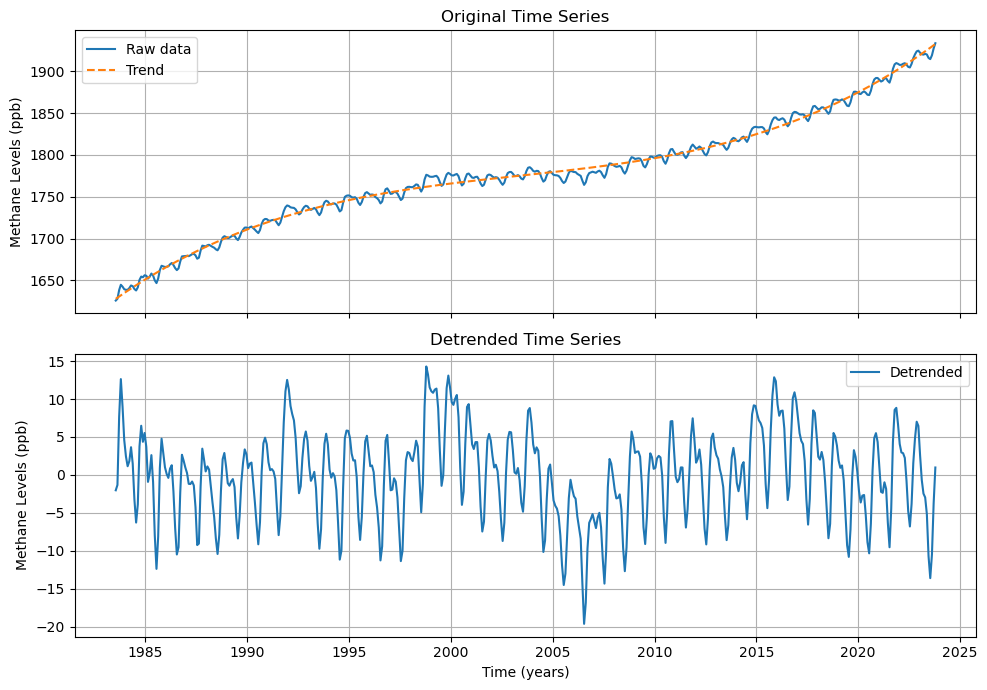

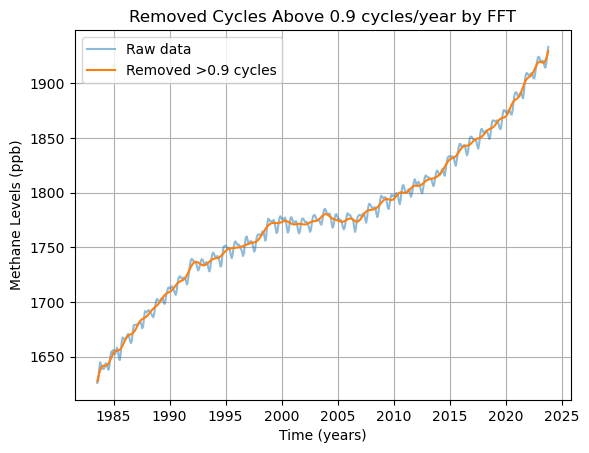

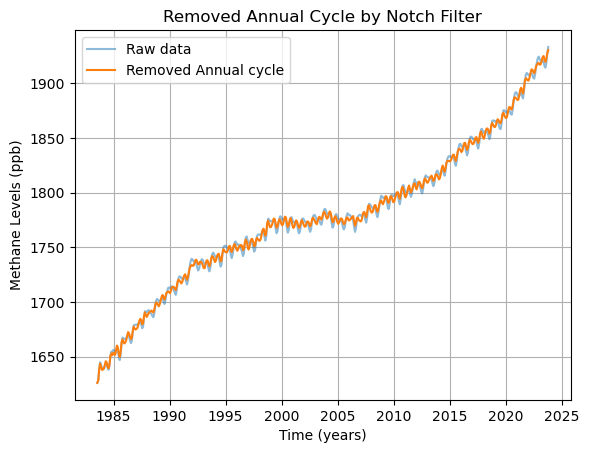

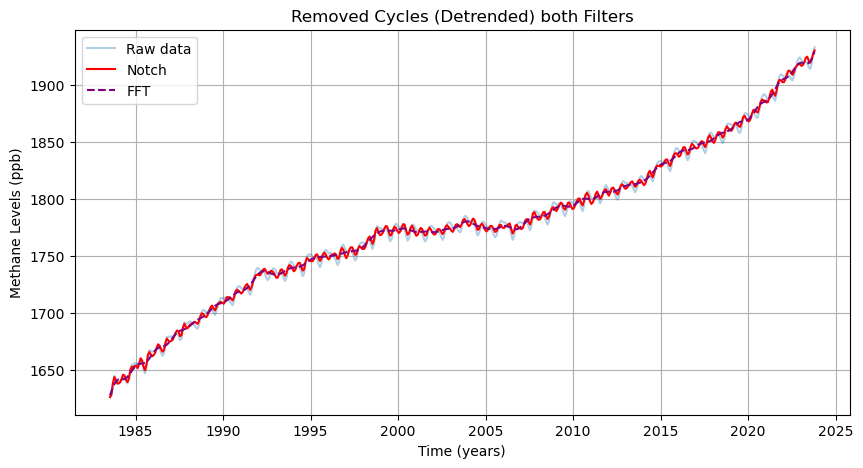

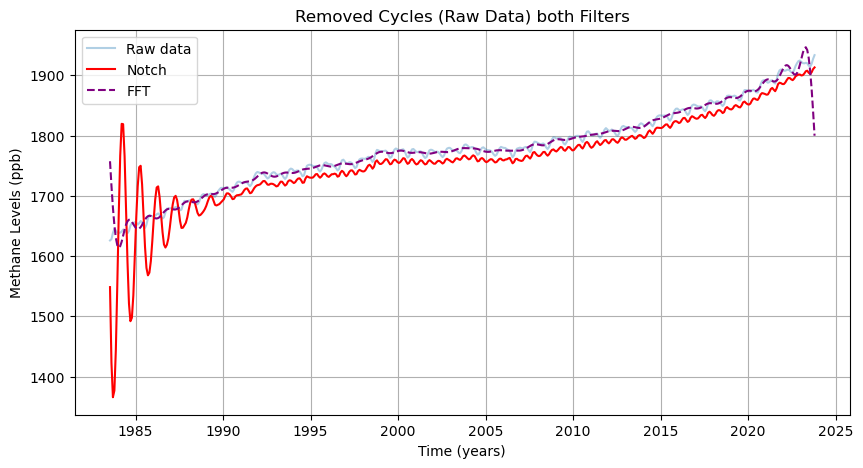

In [85]:
# Question 2: Comparing Filters on Global Methane Data

# Import libraries 
import numpy as np
import matplotlib.pyplot as plt 
import pandas as pd
import scipy.fft as fft

# Part a): Detrend Data

# Extract the data
usecols = ['decimal', 'average']
data = pd.read_csv('methane_global.csv', usecols = usecols)
time = data["decimal"].to_numpy()
methane = data["average"].to_numpy() # ppb

dt = time[1] - time[0] # Sampling rate 
N = len(methane) # number of data points

# Fit the trend 
coeffs = np.polyfit(time, methane, deg = 3)
trend = np.polyval(coeffs, time)
detrended = methane - trend

# Plot it 
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

axes[0].plot(time, methane, label = 'Raw data')
axes[0].plot(time, trend, '--', label = 'Trend')
axes[0].set_ylabel('Methane Levels (ppb)')
axes[0].set_title('Original Time Series')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(time, detrended, label='Detrended')
axes[1].set_xlabel('Time (years)')
axes[1].set_ylabel('Methane Levels (ppb)')
axes[1].set_title('Detrended Time Series')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

# Part b): Remove > 0.9 cycles per year 

# Take the Fourier transform 
detrended_fft = fft.fft(detrended)
frequencies = fft.fftfreq(len(detrended), dt) 
# remove more than 0.9 frequency
detrended_fft[np.abs(frequencies) > 0.9] = 0 # set them to zero

# Transform back into time domain 
detrend_noannual = np.real(fft.ifft(detrended_fft))

# Reconstruct 
no_annual = detrend_noannual + trend

plt.plot(time, methane, alpha = 0.5, label = 'Raw data')
plt.plot(time, no_annual, label = 'Removed >0.9 cycles')
plt.xlabel('Time (years)')
plt.ylabel('Methane Levels (ppb)')
plt.title('Removed Cycles Above 0.9 cycles/year by FFT')
plt.grid()
plt.legend()
plt.show()

# Part c): Design Notch Filter

# Define p and q and M
f_s = 12 # cycles per year 
f_0 = 1 # cycles per year
M = 1.05 
eps = 0.05
delta = 1/f_s # Sampling interval (years)
q = np.exp(1j * 2* np.pi * f_0/f_s)
p = (1 + eps)* q

# Notch filter coefficients
N = [M * np.abs(q)**2/np.abs(p)**2, -2*M * np.real(q)/np.abs(p)**2, M/np.abs(p)**2] 
D = [1, -2* np.real(p)/np.abs(p)**2, 1/np.abs(p)**2]

def ratFilter(N,D,x):
    """
    Function that returns filtered time series given 
    input x and coefficients of filter N and D
    inputs: 
    N - numerator coefficients [n0, n1,...]
    D - denominator coefficients [d0, d1, ...]
    x - input time series x[n]
    output: 
    Filtered time series using W(z) y[n]
    """
    # filtered output
    y = np.zeros_like(x, dtype=float)

    for n in range(len(x)):
        for m in range(len(N)): # for each coefficient
            if n - m >= 0: # make sure no wrapping
                y[n] += N[m] * x[n - m] 
        for k in range(1, len(D)): # starts from 1
            if n - k >= 0:
                y[n] -= D[k] * y[n - k]
    return y
    
# apply to detrended dataset 
ann_rem_notch = ratFilter(N, D, detrended)

# then add back the trend 
reconstruct_notch = ann_rem_notch + trend

# Plot reconstructed 
plt.plot(time, methane, alpha = 0.5, label = 'Raw data')
plt.plot(time, reconstruct_notch, label = 'Removed Annual cycle')
plt.xlabel('Time (years)')
plt.ylabel('Methane Levels (ppb)')
plt.title('Removed Annual Cycle by Notch Filter')
plt.legend()
plt.grid()
plt.show()

# Part d): Plot both filtered results in the same plot 
plt.figure(figsize = (10, 5))
plt.plot(time, methane, alpha = 0.35, label = 'Raw data')
plt.plot(time, reconstruct_notch, color = 'red', label = 'Notch')
plt.plot(time, no_annual, linestyle = '--', color = 'purple', label = 'FFT')
plt.xlabel('Time (years)')
plt.ylabel('Methane Levels (ppb)')
plt.title('Removed Cycles (Detrended) both Filters')
plt.grid()
plt.legend()
plt.show()

# Part e): Repeat without detrending dataset 

# Lowpass FFT:
# Take the Fourier transform of raw data
data_fft = fft.fft(methane)
frequencies = fft.fftfreq(len(methane), dt) 
# remove more than 0.9 frequency
data_fft[np.abs(frequencies) > 0.9] = 0 # set them to zero

# Transform back into time domain 
fft_noannual = np.real(fft.ifft(data_fft))

# Notch filter: 
# apply filter to raw dataset 
notch_noannual = ratFilter(N, D, methane)

# Plot both the options again 
plt.figure(figsize = (10, 5))
plt.plot(time, methane, alpha = 0.35, label = 'Raw data')
plt.plot(time, notch_noannual, color = 'red', label = 'Notch')
plt.plot(time, fft_noannual, linestyle = '--', color = 'purple', label = 'FFT')
plt.xlabel('Time (years)')
plt.ylabel('Methane Levels (ppb)')
plt.title('Removed Cycles (Raw Data) both Filters')
plt.grid()
plt.legend()
plt.show()